In [1]:
!pip install econml
!pip install doubleml
!pip install lifelines
!pip install dowhy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 40.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 532.9/532.9 kB 24.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 237.3/237.3 kB 14.4 MB/s eta 0:00:00
  Attempting uninstall: slicer
    Found existing installation: slicer 0.0.8
    Uninstalling slicer-0.0.8:
      Successfully uninstalled slicer-0.0.8
  Attempting uninstall: shap
    Found existing installation: shap 0.46.0
    Uninstalling shap-0.46.0:
      Successfully uninstalled shap-0.46.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 318.1/318.1 kB 3.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 349.3/349.3 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.5/94.5 kB 6.6 MB/s eta 0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4031 sha256=631e660fb522aaeb7c18ea12f9c1d6d9a1dea12acdea03aebf9fe845897b5707
  Stored in direct

In [2]:
import numpy as np
import pandas as pd
import xgboost as xgb
import pickle
from sklearn.cluster import DBSCAN
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import make_scorer, accuracy_score, recall_score, precision_score, f1_score, roc_auc_score, roc_curve
from imblearn.metrics import geometric_mean_score
from econml.dml import LinearDML, SparseLinearDML, CausalForestDML, KernelDML
from econml.dr import LinearDRLearner, ForestDRLearner
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from econml.score import RScorer
from econml.federated_learning import FederatedEstimator
import shap
from lifelines import KaplanMeierFitter
from sklearn.metrics import make_scorer, roc_auc_score, accuracy_score, recall_score, precision_score, f1_score
from imblearn.metrics import geometric_mean_score
from scipy.stats import ks_2samp
from imblearn.over_sampling import SMOTENC
from sklearn.preprocessing import PolynomialFeatures
from dowhy import CausalModel

In [3]:
def calculate_rscore(est, Y, T, X):
  loss_cate = est.score(Y, T, X)
  res = est.residuals_
  Yres, Tres = res[0], res[1]
  theta = np.mean(Yres) / np.mean(Tres)
  base_loss = np.mean((Yres - theta * Tres) ** 2)
  rscore = 1 - loss_cate / base_loss
  return rscore

In [4]:
def calculate_weights(data):
    if isinstance(data, np.ndarray):
        data_series = pd.Series(data)
    elif isinstance(data, pd.Series):
        data_series = data
    else:
        raise TypeError("Input must be series or array.")

    value_counts = data_series.value_counts(normalize=True)
    weights = value_counts.map(lambda x: 1 / x)
    weights_array = data_series.map(weights).values

    return weights_array

In [7]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/DML-ICU/alltime-48h-withdeath-3.0.csv')
null_ratio = df.isnull().mean()
df = df.loc[:, null_ratio <= 0.5]
print(df.shape)

(34148, 93)


In [8]:
df_copy = df.copy().drop(['median_vt','iqr_vt','median_gcs','iqr_gcs'], axis=1)
#df_copy = df_copy.dropna(thresh=len(df_copy.columns) - 2)
df_copy = df_copy.apply(lambda col: col.interpolate(method='quadratic'))
df_copy = df_copy.dropna()
#df_copy['extubationoutcome'].value_counts()
#df_copy.iloc[:,0:70].head()
#因为有ICU类别文本报错

Series.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.


In [9]:
len = df_copy['len_of_icu'].quantile(0.95)
ext = 168 #df_copy['durationhours'].quantile(0.95)
df_copy = df_copy[df_copy['len_of_icu'] <= len]
df_copy = df_copy[df_copy['durationhours'] <= ext]
df_copy.reset_index(drop=True, inplace=True)

In [10]:
df_copy.iloc[:,1:70].head()

,extubationoutcome,len_of_icu,mortality_in_icu,durationhours,gender,age,bmi,last_hr,last_rr,last_apm,...,iqr_be,median_wbc,iqr_wbc,median_hb,iqr_hb,median_plt,iqr_plt,median_temp,iqr_temp,charlson_comorbidity_index
0,1,39.246667,1,11.833333,1,66,33.085938,82.0,22.0,76.759570,...,0.325420,12.352094,-0.035893,9.86622,-0.009886,140.783868,0.20898,98.7,1.30,8
1,1,27.243056,0,3.166667,1,69,19.618382,80.0,17.0,71.000000,...,0.000000,10.900000,0.000000,11.00000,0.000000,177.000000,0.00000,96.0,0.00,3
2,1,27.657500,0,18.466667,0,68,17.134446,95.0,15.0,65.721291,...,-0.476261,10.800000,0.000000,12.40000,0.000000,245.000000,0.00000,98.8,1.40,2
3,1,31.441667,1,14.316667,1,47,23.721140,95.0,19.0,68.000000,...,0.000000,5.000000,0.000000,7.00000,0.000000,161.000000,0.00000,98.2,0.65,2
4,1,29.613333,0,7.000000,1,71,27.900518,80.0,17.0,76.000000,...,1.500000,11.950000,3.250000,11.70000,0.700000,140.000000,8.00000,98.0,0.50,4


In [ ]:
# 获取病人的基础病特征
comorbidity_cols = df_copy.iloc[:, 72:].columns  # 基础病列名

# 创建一个空的列表来收集重采样后的数据
rows = []

# 遍历每个病人，重采样每个有基础病的情况
for _, row in df_copy.iterrows():
    # 获取病人所有的基础病类型
    conditions = []
    for col in comorbidity_cols:
        if row[col] == 1:
            conditions.append(col)  # 基础病列名即为疾病名

    # 如果有多个基础病，就生成多条记录
    for condition in conditions:
        new_row = row.copy()
        new_row['comorbidity_type'] = condition
        rows.append(new_row)

# 将所有收集到的行合并为 DataFrame
expanded_df = pd.DataFrame(rows)
expanded_df = expanded_df.drop(expanded_df.columns[72:89], axis=1)

expanded_df.head()

,stay_id,extubationoutcome,len_of_icu,mortality_in_icu,durationhours,gender,age,bmi,last_hr,last_rr,...,median_hb,iqr_hb,median_plt,iqr_plt,median_temp,iqr_temp,charlson_comorbidity_index,age_score,myocardial_infarct,comorbidity_type
0,30000213,1,39.246667,0,11.833333,1,66,33.085938,82.0,22.0,...,9.866373,-0.009749,140.604851,0.163524,98.7,1.3,8,2,0,congestive_heart_failure
0,30000213,1,39.246667,0,11.833333,1,66,33.085938,82.0,22.0,...,9.866373,-0.009749,140.604851,0.163524,98.7,1.3,8,2,0,chronic_pulmonary_disease
0,30000213,1,39.246667,0,11.833333,1,66,33.085938,82.0,22.0,...,9.866373,-0.009749,140.604851,0.163524,98.7,1.3,8,2,0,diabetes_without_cc
0,30000213,1,39.246667,0,11.833333,1,66,33.085938,82.0,22.0,...,9.866373,-0.009749,140.604851,0.163524,98.7,1.3,8,2,0,diabetes_with_cc
0,30000213,1,39.246667,0,11.833333,1,66,33.085938,82.0,22.0,...,9.866373,-0.009749,140.604851,0.163524,98.7,1.3,8,2,0,renal_disease


In [ ]:
expanded_X = np.array(expanded_df.iloc[:,5:69].values,dtype=float)
expanded_Y = np.array(expanded_df['extubationoutcome'].values,dtype=float)
expanded_T = np.array(expanded_df['durationhours'].values,dtype=float)
expanded_P = np.array(expanded_df['mortality_in_icu'].values,dtype=float)
expanded_L = np.array(expanded_df['len_of_icu'].values,dtype=float)

scaler = StandardScaler()
expanded_X = scaler.fit_transform(expanded_X)

In [11]:
# Verify the mapping
category_mapping = dict(enumerate(df_copy['last_careunit'].astype('category').cat.categories))

print(category_mapping)
df_copy['last_careunit'] = df_copy['last_careunit'].astype('category').cat.codes

{0: 'Cardiac Vascular Intensive Care Unit (CVICU)', 1: 'Coronary Care Unit (CCU)', 2: 'Intensive Care Unit (ICU)', 3: 'Med/Surg', 4: 'Medical Intensive Care Unit (MICU)', 5: 'Medical/Surgical Intensive Care Unit (MICU/SICU)', 6: 'Medicine', 7: 'Medicine/Cardiology Intermediate', 8: 'Neuro Intermediate', 9: 'Neuro Stepdown', 10: 'Neuro Surgical Intensive Care Unit (Neuro SICU)', 11: 'PACU', 12: 'Surgery/Trauma', 13: 'Surgery/Vascular/Intermediate', 14: 'Surgical Intensive Care Unit (SICU)', 15: 'Trauma SICU (TSICU)'}


In [12]:
X = np.array(df_copy.iloc[:,5:69].values,dtype=float)
Y = np.array(df_copy['extubationoutcome'].values,dtype=float)
T = np.array(df_copy['durationhours'].values,dtype=float)
P = np.array(df_copy['mortality_in_icu'].values,dtype=float)
L = np.array(df_copy['len_of_icu'].values,dtype=float)

bins = [0, 4, 8, 12, 16, 20, 24, np.inf]
labels = ['0-4h', '4-8h', '8-12h', '12-16h', '16-20h', '20-24h', '>24h']
df_copy['time_category'] = pd.cut(T, bins=bins, labels=labels, right=False)

df_minority = df_copy[df_copy['time_category']=='>24h']

#scaler = StandardScaler()
#X = scaler.fit_transform(X)

categorical_vars = [
    'mortality_in_icu', 'gender', 'charlson_comorbidity_index', 'myocardial_infarct',
    'congestive_heart_failure', 'peripheral_vascular_disease', 'cerebrovascular_disease', 'dementia',
    'chronic_pulmonary_disease', 'rheumatic_disease', 'peptic_ulcer_disease', 'mild_liver_disease',
    'diabetes_without_cc', 'diabetes_with_cc', 'paraplegia', 'renal_disease', 'malignant_cancer',
    'severe_liver_disease', 'metastatic_solid_tumor', 'aids'
]

weights_Y = calculate_weights(Y)
weights_P = calculate_weights(P)

In [13]:
# 为灵敏度分析做铺垫
n_samples = X.shape[0]
random_variable = np.random.normal(loc=0, scale=1, size=n_samples)
random_variable = random_variable.reshape(-1, 1)
X_with_random = np.hstack((X, random_variable)) # 加上一个随机变量

X_with_confounder = np.array(df_copy.iloc[:,5:70].values,dtype=float) # 加上一个混杂变量
scaler = StandardScaler()
X_with_confounder = scaler.fit_transform(X_with_confounder)

In [14]:
X_Y0 = X[Y == 0] # Extubation Failure
T_Y0 = T[Y == 0]
P_Y0 = P[Y == 0]
weights_P_Y0 = calculate_weights(P_Y0)

X_Y1 = X[Y == 1] # Extubation Success
T_Y1 = T[Y == 1]
P_Y1 = P[Y == 1]
weights_P_Y1 = calculate_weights(P_Y1)

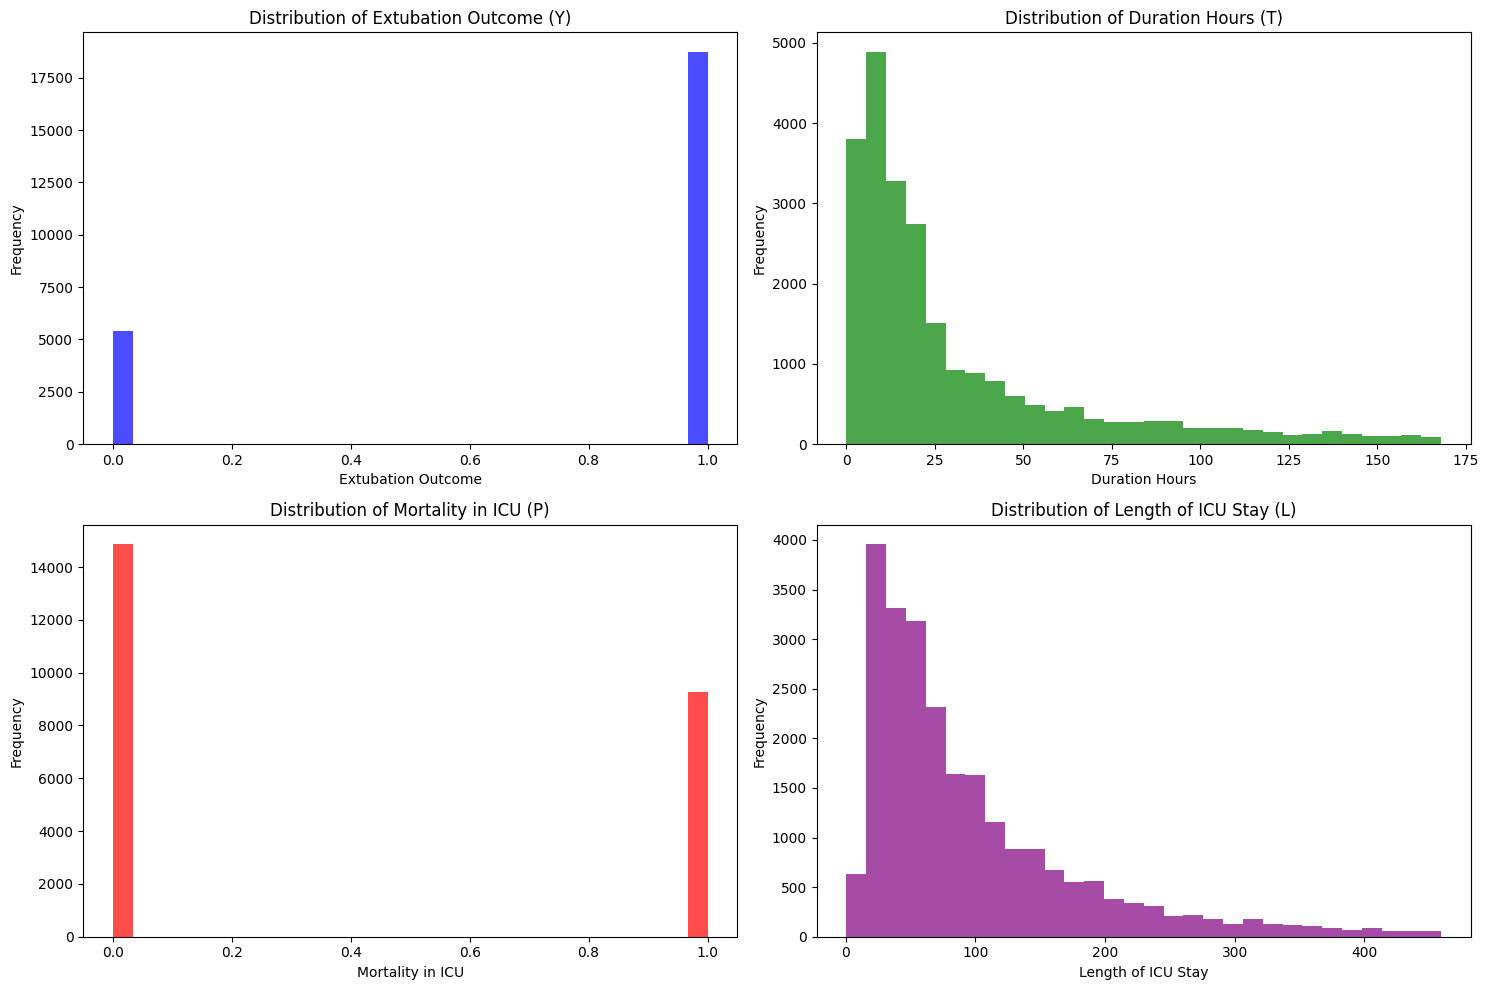

In [ ]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
plt.hist(Y, bins=30, color='blue', alpha=0.7)
plt.title('Distribution of Extubation Outcome (Y)')
plt.xlabel('Extubation Outcome')
plt.ylabel('Frequency')

plt.subplot(2, 2, 2)
plt.hist(T, bins=30, color='green', alpha=0.7)
plt.title('Distribution of Duration Hours (T)')
plt.xlabel('Duration Hours')
plt.ylabel('Frequency')

plt.subplot(2, 2, 3)
plt.hist(P, bins=30, color='red', alpha=0.7)
plt.title('Distribution of Mortality in ICU (P)')
plt.xlabel('Mortality in ICU')
plt.ylabel('Frequency')

plt.subplot(2, 2, 4)
plt.hist(L, bins=30, color='purple', alpha=0.7)
plt.title('Distribution of Length of ICU Stay (L)')
plt.xlabel('Length of ICU Stay')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


In [ ]:
SMOTE = SMOTENC(categorical_features=categorical_vars, random_state=42)
X_resampled, Y_resampled = SMOTE.fit_resample(df_copy.iloc[:,2:89], df_copy['extubationoutcome'])
Xnew = np.array(X_resampled.iloc[:,3:67].values,dtype=float)
Tnew = np.array(X_resampled['durationhours'].values,dtype=float)
Pnew = np.array(X_resampled['mortality_in_icu'].values,dtype=float)
Lnew = np.array(X_resampled['len_of_icu'].values,dtype=float)
Ynew = np.array(Y_resampled.values,dtype=float)

In [ ]:
df_resampled = X_resampled.copy()
df_resampled.insert(0, 'extubationoutcome', Y_resampled)
df_resampled['last_careunit'] = df_resampled['last_careunit'].map(lambda x: category_mapping[x])
bins = [0, 4, 8, 12, 16, 20, 24, np.inf]
labels = ['0-4h', '4-8h', '8-12h', '12-16h', '16-20h', '20-24h', '>24h']
df_resampled['time_category'] = pd.cut(Tnew, bins=bins, labels=labels, right=False)
df_resampled.iloc[:,4:68].head()

,gender,age,bmi,last_hr,last_rr,last_apm,last_pao2,last_fio2,last_paco2,last_aph,...,median_be,iqr_be,median_wbc,iqr_wbc,median_hb,iqr_hb,median_plt,iqr_plt,median_temp,iqr_temp
0,1,66,33.085938,82.0,22.0,76.611675,79.0,50.0,42.0,7.37,...,-2.175956,0.283681,12.343446,-0.037856,9.866373,-0.009749,140.604851,0.163524,98.7,1.30
1,1,69,19.618382,80.0,17.0,71.000000,134.0,40.0,40.0,7.39,...,0.000000,0.000000,10.900000,0.000000,11.000000,0.000000,177.000000,0.000000,96.0,0.00
2,0,68,16.541435,95.0,15.0,66.164975,124.0,40.0,31.0,7.49,...,3.527867,-0.351042,10.800000,0.000000,12.400000,0.000000,245.000000,0.000000,98.8,1.40
3,1,47,22.337446,95.0,19.0,68.000000,214.0,40.0,44.0,7.44,...,5.000000,0.000000,5.000000,0.000000,7.000000,0.000000,161.000000,0.000000,98.2,0.65
4,1,71,27.900518,80.0,17.0,76.000000,170.0,50.0,45.0,7.34,...,1.000000,1.500000,11.950000,3.250000,11.700000,0.700000,140.000000,8.000000,98.0,0.50


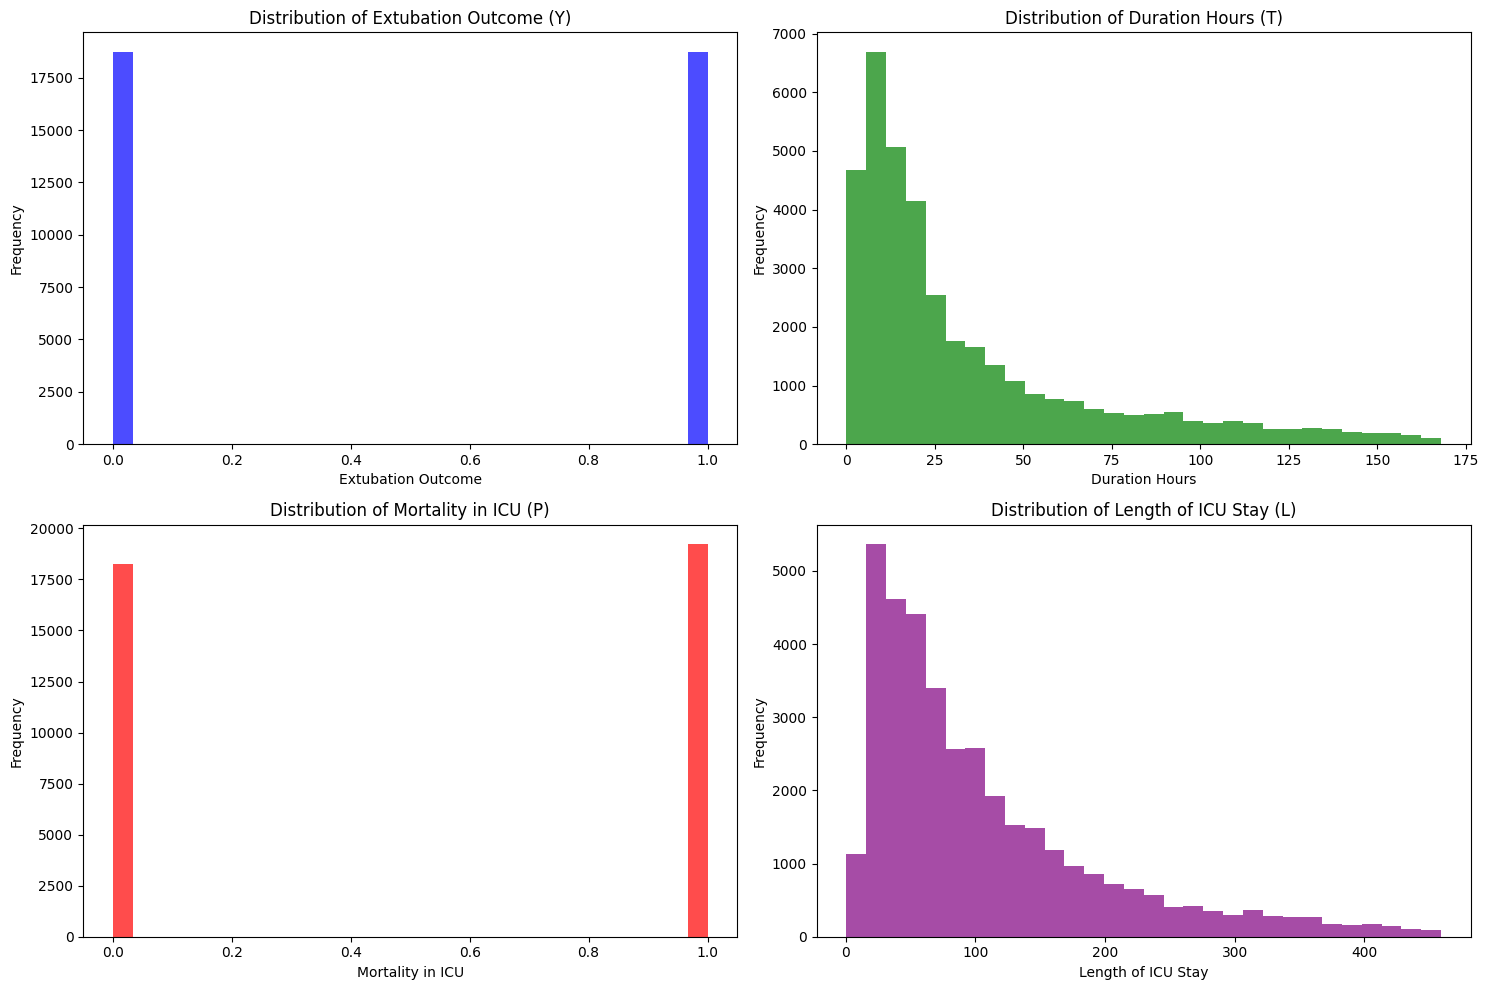

In [ ]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
plt.hist(Ynew, bins=30, color='blue', alpha=0.7)
plt.title('Distribution of Extubation Outcome (Y)')
plt.xlabel('Extubation Outcome')
plt.ylabel('Frequency')

plt.subplot(2, 2, 2)
plt.hist(Tnew, bins=30, color='green', alpha=0.7)
plt.title('Distribution of Duration Hours (T)')
plt.xlabel('Duration Hours')
plt.ylabel('Frequency')

plt.subplot(2, 2, 3)
plt.hist(Pnew, bins=30, color='red', alpha=0.7)
plt.title('Distribution of Mortality in ICU (P)')
plt.xlabel('Mortality in ICU')
plt.ylabel('Frequency')

plt.subplot(2, 2, 4)
plt.hist(Lnew, bins=30, color='purple', alpha=0.7)
plt.title('Distribution of Length of ICU Stay (L)')
plt.xlabel('Length of ICU Stay')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [ ]:
unique, counts = np.unique(df_copy['age_score'].values, return_counts=True)
print(unique, counts)

[0 1 2 3 4] [3892 4121 6092 5594 4422]


In [ ]:
def plot_kaplan_meier(group, group_name):
    kmf = KaplanMeierFitter()
    plt.figure(figsize=(16, 8))
    for value in group.unique():
        ix = group == value
        kmf.fit(T[ix], event_observed=Y[ix], label=f"{value}")
        kmf.plot_survival_function()
    plt.title(f"Kaplan-Meier Curve by {group_name}")
    plt.xlabel("Duration (hours)")
    plt.ylabel("Survival Probability")
    plt.grid(True)
    plt.show()

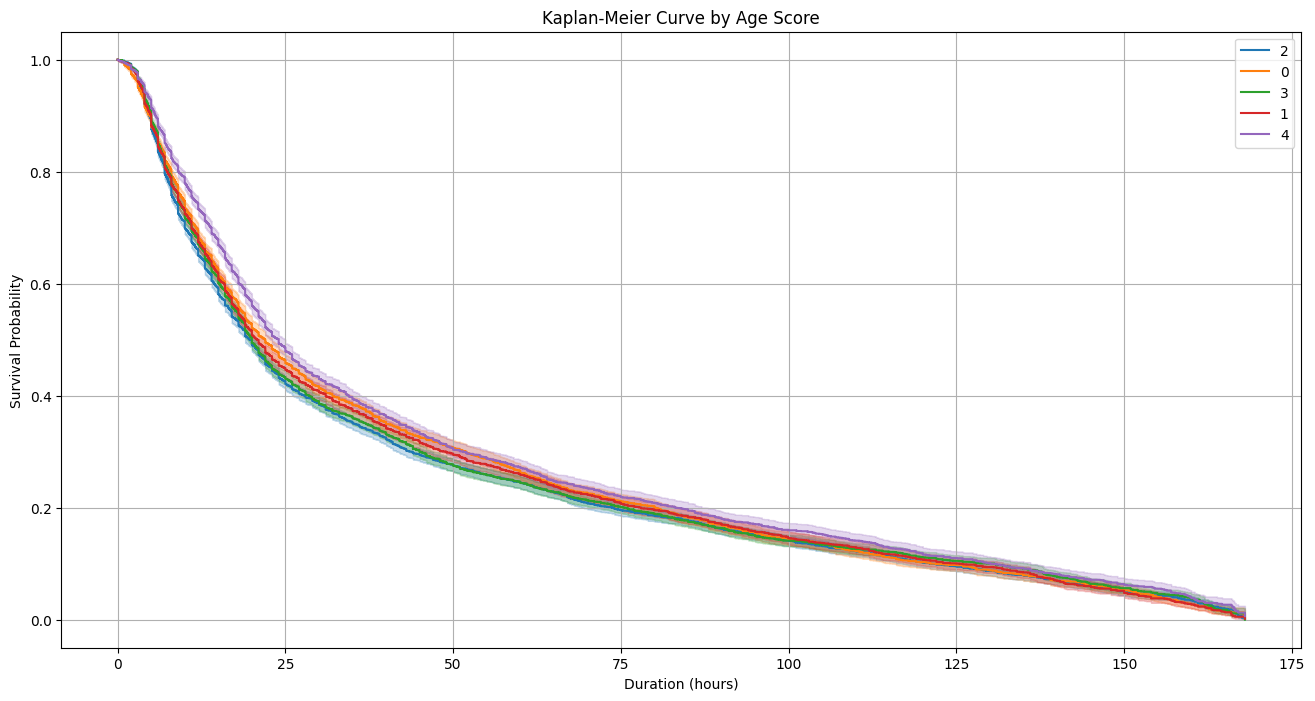

In [ ]:
# 绘制年龄分数的 Kaplan-Meier 曲线
plot_kaplan_meier(df_copy['age_score'], 'Age Score')

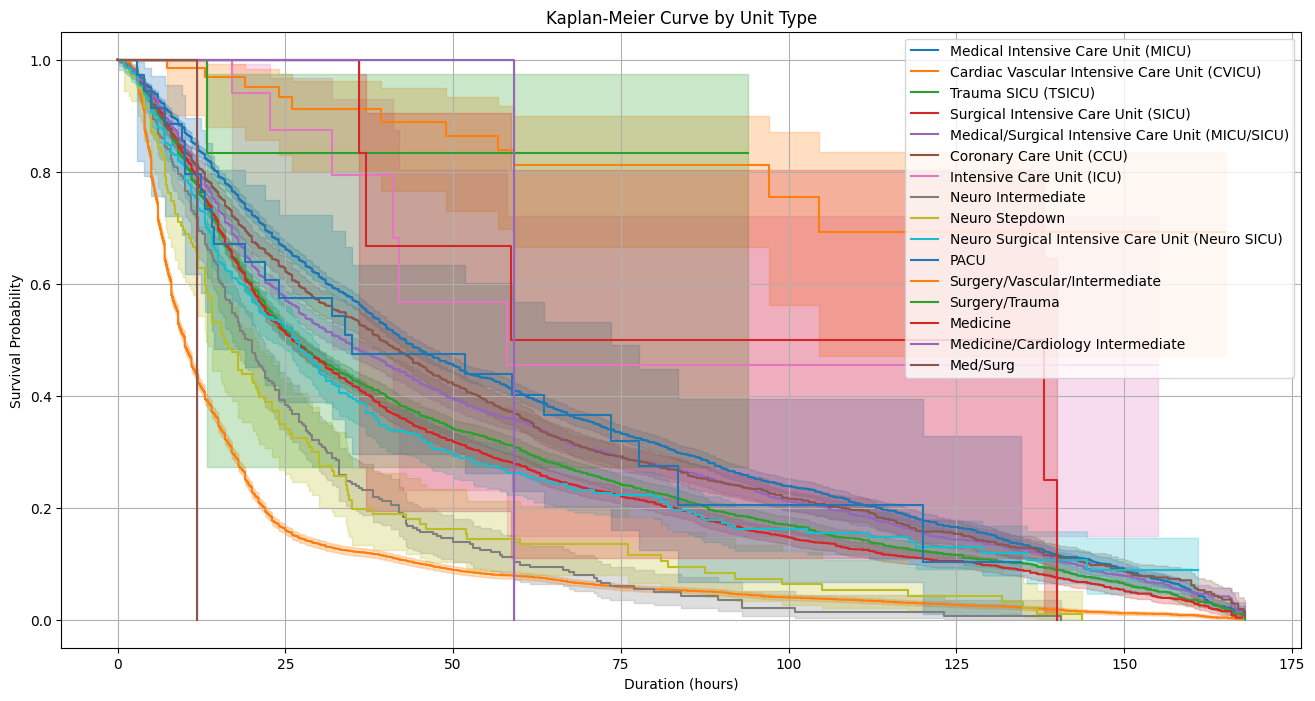

In [ ]:
# 绘制 ICU 类型的 Kaplan-Meier 曲线
plot_kaplan_meier(df_copy['last_careunit'], 'Unit Type')

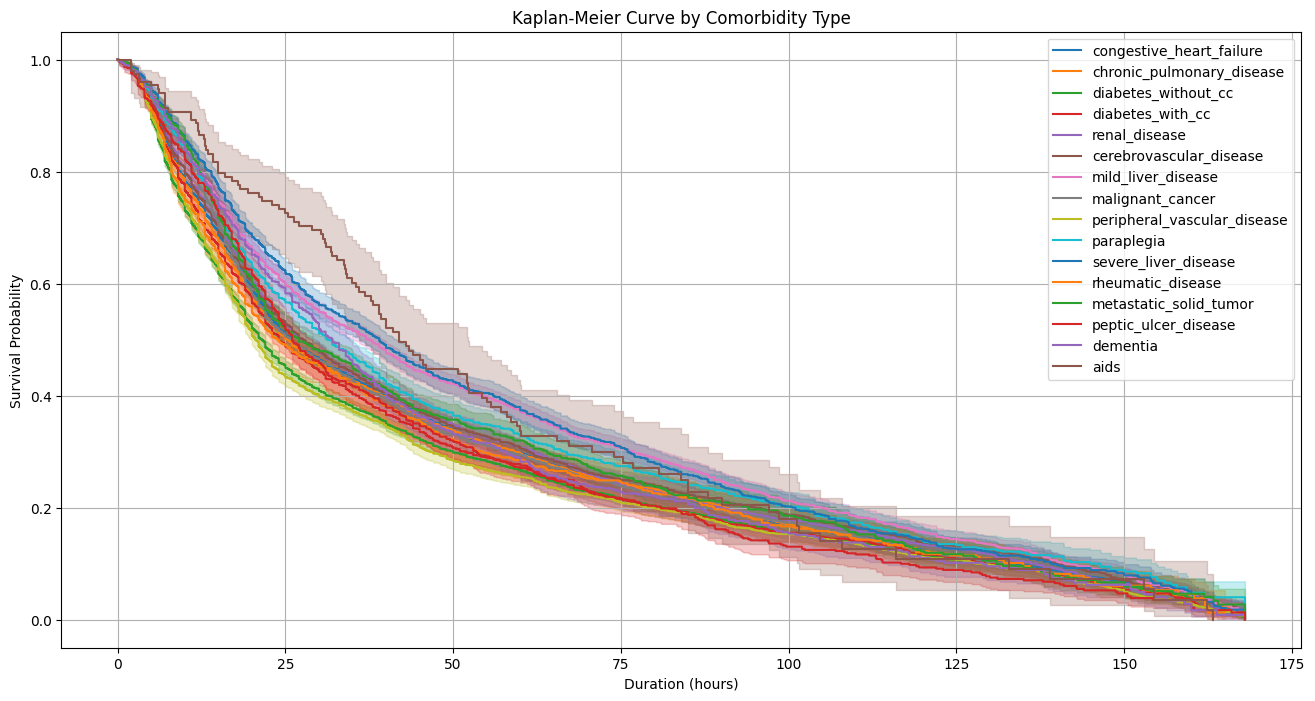

In [ ]:
kmf = KaplanMeierFitter()
plt.figure(figsize=(16, 8))
for value in expanded_df['comorbidity_type'].unique():
    ix = expanded_df['comorbidity_type'] == value
    kmf.fit(expanded_T[ix], event_observed=expanded_Y[ix], label=f"{value}")
    kmf.plot_survival_function()
plt.title(f"Kaplan-Meier Curve by Comorbidity Type")
plt.xlabel("Duration (hours)")
plt.ylabel("Survival Probability")
plt.grid(True)
plt.show()

# 网格化搜索

In [15]:
xgb_classifier = xgb.XGBClassifier(
    objective='binary:logistic',
    max_depth=6,                  # 树的最大深度
    learning_rate=0.01,            # 学习率
    n_estimators=200,             # 树的数量
    verbosity=1,                  # 输出日志信息
    booster='gbtree',             # 使用的提升方法（梯度增强树）
    gamma=1,                      # 惩罚项系数
    min_child_weight=1,           # 最小叶子节点样本权重和
    subsample=0.9,                # 子样本比例
    colsample_bytree=0.8,         # 每棵树随机采样的特征比例
    reg_alpha=1,                  # L1 正则化系数
    reg_lambda=1,                 # L2 正则化系数
    random_state=42               # 随机种子
)

In [16]:
def create_dataset_vs_24h(df, treatment_label):
    """
    根据给定的时间区间创建处理组 (T=1) 和对照组 (T=0) 数据集,
    对照组固定为 '>24h' 时间区间.
    :param df: 数据框
    :param treatment_label: 时间区间标签, 用于选择处理组
    :return: 新的数据集，其中 T=1 是处理组，T=0 是 '>24h' 对照组
    """
    # 处理组 (T=1)
    treatment_group = df[df['time_category'] != '>24h'].copy()
    treatment_group['T'] = 1

    # 对照组 (T=0)，固定为 '>24h'
    control_group = df[df['time_category'] == '>24h'].copy()
    control_group['T'] = 0

    # 合并处理组和对照组
    combined_df = pd.concat([treatment_group, control_group], axis=0).reset_index(drop=True)

    # 随机打乱数据集，确保处理组和对照组混合分布
    combined_df = combined_df.sample(frac=1, random_state=42).reset_index(drop=True)

    return combined_df

In [ ]:
df_new = create_24h_vs_24h(df_copy)
T = np.array(df_new['T'])
X = np.array(df_new.iloc[:,5:69].values,dtype=float)
Y = np.array(df_new['extubationoutcome'].values,dtype=float)
X_train, X_test, y_train, y_test, t_train, t_test = train_test_split(X, Y, T, test_size=0.2, random_state=42)

scorers = {
    'accuracy': make_scorer(accuracy_score),
    'recall': make_scorer(recall_score, average='macro'),
    'precision': make_scorer(precision_score, average='macro'),
    'f1': make_scorer(f1_score, average='macro'),
    'gmean': make_scorer(geometric_mean_score, average='macro'),
    'auc': make_scorer(roc_auc_score, needs_proba=True)
}

The `needs_threshold` and `needs_proba` parameter are deprecated in version 1.4 and will be removed in 1.6. You can either let `response_method` be `None` or set it to `predict` to preserve the same behaviour.


In [ ]:
from sklearn.utils.class_weight import compute_sample_weight

# 计算 sample weight，'balanced' 会自动根据类别分布计算权重
sample_weights = compute_sample_weight('balanced', y_train)

# 检查权重分布
print(f"Sample Weights: {sample_weights}")

Sample Weights: [0.65999462 0.65999462 0.65999462 ... 0.65999462 0.65999462 0.65999462]


In [ ]:
xgb_grid = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [5, 6, 7, 8],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.7, 0.8, 0.9]
}

xgb_grid_search = GridSearchCV(estimator=xgb_classifier, param_grid=xgb_grid, cv=3, n_jobs=-1, verbose=1, scoring=scorers, refit='auc')

xgb_grid_search.fit(X_train, y_train, sample_weight=sample_weights)
cv_results = xgb_grid_search.cv_results_
print("Best XGBoost parameters for Y:", xgb_grid_search.best_params_)
metrics = ['accuracy', 'recall', 'precision', 'f1', 'gmean', 'auc']
for metric in metrics:
    mean_score = np.mean(cv_results[f'mean_test_{metric}'])
    std_score = np.std(cv_results[f'mean_test_{metric}'])
    print(f"{metric.capitalize()} Mean: {mean_score:.4f}, {metric.capitalize()} Std: {std_score:.4f}")

xgb_grid_search.fit(X_train, t_train)
cv_results = xgb_grid_search.cv_results_
print("Best XGBoost parameters for T:", xgb_grid_search.best_params_)
metrics = ['accuracy', 'recall', 'precision', 'f1', 'gmean', 'auc']
for metric in metrics:
    mean_score = np.mean(cv_results[f'mean_test_{metric}'])
    std_score = np.std(cv_results[f'mean_test_{metric}'])
    print(f"{metric.capitalize()} Mean: {mean_score:.4f}, {metric.capitalize()} Std: {std_score:.4f}")

Fitting 3 folds for each of 144 candidates, totalling 432 fits
Best XGBoost parameters for Y: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 100, 'subsample': 0.8}
Accuracy Mean: 0.7959, Accuracy Std: 0.0136
Recall Mean: 0.7310, Recall Std: 0.0088
Precision Mean: 0.7260, Precision Std: 0.0141
F1 Mean: 0.7266, F1 Std: 0.0067
Gmean Mean: 0.7310, Gmean Std: 0.0088
Auc Mean: 0.7310, Auc Std: 0.0088
Fitting 3 folds for each of 144 candidates, totalling 432 fits
Best XGBoost parameters for T: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 400, 'subsample': 0.9}
Accuracy Mean: 0.8607, Accuracy Std: 0.0087
Recall Mean: 0.8497, Recall Std: 0.0114
Precision Mean: 0.8539, Precision Std: 0.0081
F1 Mean: 0.8516, F1 Std: 0.0101
Gmean Mean: 0.8497, Gmean Std: 0.0114
Auc Mean: 0.8497, Auc Std: 0.0114


In [ ]:
mlp_grid = {
    'hidden_layer_sizes': [(50,), (100,), (100, 50)],
    'activation': ['relu', 'tanh'],
    'solver': ['adam', 'sgd'],
    'learning_rate': ['constant', 'adaptive'],
    'max_iter': [200, 300]
}

mlp_grid_search = GridSearchCV(estimator=MLPClassifier(random_state=42), param_grid=mlp_grid, cv=3, n_jobs=-1, verbose=1, scoring=scorers, refit='accuracy')
mlp_grid_search.fit(X_train, y_train)

cv_results = mlp_grid_search.cv_results_
print("Best MLP parameters for Y:", mlp_grid_search.best_params_)
metrics = ['accuracy', 'recall', 'precision', 'f1', 'gmean', 'auc']
for metric in metrics:
    mean_score = np.mean(cv_results[f'mean_test_{metric}'])
    std_score = np.std(cv_results[f'mean_test_{metric}'])
    print(f"{metric.capitalize()} Mean: {mean_score:.4f}, {metric.capitalize()} Std: {std_score:.4f}")

mlp_grid_search.fit(X_train, t_train)

cv_results = mlp_grid_search.cv_results_
print("Best MLP parameters for T:", mlp_grid_search.best_params_)
metrics = ['accuracy', 'recall', 'precision', 'f1', 'gmean', 'auc']
for metric in metrics:
    mean_score = np.mean(cv_results[f'mean_test_{metric}'])
    std_score = np.std(cv_results[f'mean_test_{metric}'])
    print(f"{metric.capitalize()} Mean: {mean_score:.4f}, {metric.capitalize()} Std: {std_score:.4f}")

Fitting 3 folds for each of 48 candidates, totalling 144 fits


invalid value encountered in cast


Best MLP parameters for Y: {'activation': 'relu', 'hidden_layer_sizes': (100, 50), 'learning_rate': 'constant', 'max_iter': 200, 'solver': 'adam'}
Accuracy Mean: 0.7885, Accuracy Std: 0.0219
Recall Mean: 0.6095, Recall Std: 0.0669
Precision Mean: 0.6903, Precision Std: 0.1276
F1 Mean: 0.6044, F1 Std: 0.1019
Gmean Mean: 0.6095, Gmean Std: 0.0669
Auc Mean: 0.6095, Auc Std: 0.0669
Fitting 3 folds for each of 48 candidates, totalling 144 fits


invalid value encountered in cast


Best MLP parameters for T: {'activation': 'tanh', 'hidden_layer_sizes': (100,), 'learning_rate': 'constant', 'max_iter': 200, 'solver': 'adam'}
Accuracy Mean: 0.7417, Accuracy Std: 0.0762
Recall Mean: 0.7016, Recall Std: 0.1205
Precision Mean: 0.6829, Precision Std: 0.1681
F1 Mean: 0.6714, F1 Std: 0.1690
Gmean Mean: 0.7016, Gmean Std: 0.1205
Auc Mean: 0.7016, Auc Std: 0.1205


In [ ]:
rf_grid = {
    'n_estimators': [200, 300],
    'max_depth': [20, 30],
    'min_samples_split': [5, 10],
    'min_samples_leaf': [2, 4]
}

rf_grid_search = GridSearchCV(estimator=RandomForestClassifier(random_state=42), param_grid=rf_grid, cv=5, n_jobs=-1, verbose=1, scoring=scorers, refit='accuracy')

rf_grid_search.fit(X_train, y_train, sample_weight=sample_weights)
cv_results = rf_grid_search.cv_results_
print("Best RF parameters for Y:", rf_grid_search.best_params_)
metrics = ['accuracy', 'recall', 'precision', 'f1', 'gmean', 'auc']
for metric in metrics:
    mean_score = np.mean(cv_results[f'mean_test_{metric}'])
    std_score = np.std(cv_results[f'mean_test_{metric}'])
    print(f"{metric.capitalize()} Mean: {mean_score:.4f}, {metric.capitalize()} Std: {std_score:.4f}")

rf_grid_search.fit(X_train, t_train)
cv_results = rf_grid_search.cv_results_
print("Best RF parameters for T:", rf_grid_search.best_params_)
metrics = ['accuracy', 'recall', 'precision', 'f1', 'gmean', 'auc']
for metric in metrics:
    mean_score = np.mean(cv_results[f'mean_test_{metric}'])
    std_score = np.std(cv_results[f'mean_test_{metric}'])
    print(f"{metric.capitalize()} Mean: {mean_score:.4f}, {metric.capitalize()} Std: {std_score:.4f}")

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best RF parameters for Y: {'max_depth': 30, 'min_samples_leaf': 4, 'min_samples_split': 5, 'n_estimators': 300}
Accuracy Mean: 0.8196, Accuracy Std: 0.0008
Recall Mean: 0.6855, Recall Std: 0.0124
Precision Mean: 0.7779, Precision Std: 0.0089
F1 Mean: 0.7102, F1 Std: 0.0107
Gmean Mean: 0.6855, Gmean Std: 0.0124
Auc Mean: 0.6855, Auc Std: 0.0124
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best RF parameters for T: {'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 300}
Accuracy Mean: 0.8562, Accuracy Std: 0.0007
Recall Mean: 0.8441, Recall Std: 0.0008
Precision Mean: 0.8496, Precision Std: 0.0007
F1 Mean: 0.8466, F1 Std: 0.0007
Gmean Mean: 0.8441, Gmean Std: 0.0008
Auc Mean: 0.8441, Auc Std: 0.0008


In [ ]:
svm_grid = {
    'C': [10],
    'kernel': ['linear'],
    'gamma': ['scale'],
    'degree': [3]
}

svm_grid_search = GridSearchCV(estimator=SVC(random_state=42), param_grid=svm_grid, cv=2, n_jobs=-1, verbose=1, scoring=scorers, refit='accuracy')

svm_grid_search.fit(X_train, y_train, sample_weight=sample_weights)
cv_results = svm_grid_search.cv_results_
print("Best SVM parameters for T:", svm_grid_search.best_params_)
metrics = ['accuracy', 'recall', 'precision', 'f1', 'gmean', 'auc']
for metric in metrics:
    mean_score = np.mean(cv_results[f'mean_test_{metric}'])
    std_score = np.std(cv_results[f'mean_test_{metric}'])
    print(f"{metric.capitalize()} Mean: {mean_score:.4f}, {metric.capitalize()} Std: {std_score:.4f}")

svm_grid_search.fit(X_train, t_train)
cv_results = svm_grid_search.cv_results_
print("Best SVM parameters for T:", svm_grid_search.best_params_)
metrics = ['accuracy', 'recall', 'precision', 'f1', 'gmean', 'auc']
for metric in metrics:
    mean_score = np.mean(cv_results[f'mean_test_{metric}'])
    std_score = np.std(cv_results[f'mean_test_{metric}'])
    print(f"{metric.capitalize()} Mean: {mean_score:.4f}, {metric.capitalize()} Std: {std_score:.4f}")

In [ ]:
lr_grid = {
    'penalty': ['l1', 'l2', None],
    'C': [0.1, 1, 10],
    'solver': ['saga'],
    'max_iter': [200, 500]  # 增大迭代次数
}

lr_grid_search = GridSearchCV(estimator=LogisticRegression(random_state=42), param_grid=lr_grid, cv=5, n_jobs=-1, verbose=1, scoring=scorers, refit='accuracy')
lr_grid_search.fit(X_train, y_train, sample_weight=sample_weights)

cv_results = lr_grid_search.cv_results_
print("Best LR parameters for Y:", lr_grid_search.best_params_)
metrics = ['accuracy', 'recall', 'precision', 'f1', 'gmean', 'auc']
for metric in metrics:
    mean_score = np.mean(cv_results[f'mean_test_{metric}'])
    std_score = np.std(cv_results[f'mean_test_{metric}'])
    print(f"{metric.capitalize()} Mean: {mean_score:.4f}, {metric.capitalize()} Std: {std_score:.4f}")

lr_grid_search.fit(X_train, t_train)
cv_results = lr_grid_search.cv_results_
print("Best LR parameters for T:", lr_grid_search.best_params_)
metrics = ['accuracy', 'recall', 'precision', 'f1', 'gmean', 'auc']
for metric in metrics:
    mean_score = np.mean(cv_results[f'mean_test_{metric}'])
    std_score = np.std(cv_results[f'mean_test_{metric}'])
    print(f"{metric.capitalize()} Mean: {mean_score:.4f}, {metric.capitalize()} Std: {std_score:.4f}")

Fitting 5 folds for each of 18 candidates, totalling 90 fits


The max_iter was reached which means the coef_ did not converge


Best LR parameters for Y: {'C': 0.1, 'max_iter': 500, 'penalty': 'l1', 'solver': 'saga'}
Accuracy Mean: 0.7545, Accuracy Std: 0.0000
Recall Mean: 0.5001, Recall Std: 0.0002
Precision Mean: 0.4986, Precision Std: 0.0033
F1 Mean: 0.4362, F1 Std: 0.0005
Gmean Mean: 0.5001, Gmean Std: 0.0002
Auc Mean: 0.6119, Auc Std: 0.0004
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best LR parameters for T: {'C': 0.1, 'max_iter': 500, 'penalty': 'l1', 'solver': 'saga'}
Accuracy Mean: 0.6176, Accuracy Std: 0.0000
Recall Mean: 0.5001, Recall Std: 0.0000
Precision Mean: 0.5249, Precision Std: 0.0083
F1 Mean: 0.3830, F1 Std: 0.0001
Gmean Mean: 0.5001, Gmean Std: 0.0000
Auc Mean: 0.5741, Auc Std: 0.0015


The max_iter was reached which means the coef_ did not converge


In [ ]:
lr_grid = {
    'penalty': ['l1', 'l2', None],
    'C': [0.1, 1, 10],
    'solver': ['saga'],
    'max_iter': [500]  # 增大迭代次数
}
lr_grid_search = GridSearchCV(estimator=LogisticRegression(random_state=42), param_grid=lr_grid, cv=5, n_jobs=-1, verbose=1, scoring=scorers, refit='accuracy')
lr_grid_search.fit(X_train, t_train)
cv_results = lr_grid_search.cv_results_
print("Best LR parameters for T:", lr_grid_search.best_params_)
metrics = ['accuracy', 'recall', 'precision', 'f1', 'gmean', 'auc']
for metric in metrics:
    mean_score = np.mean(cv_results[f'mean_test_{metric}'])
    std_score = np.std(cv_results[f'mean_test_{metric}'])
    print(f"{metric.capitalize()} Mean: {mean_score:.4f}, {metric.capitalize()} Std: {std_score:.4f}")

Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best LR parameters for T: {'C': 0.1, 'max_iter': 500, 'penalty': 'l1', 'solver': 'saga'}
Accuracy Mean: 0.6176, Accuracy Std: 0.0000
Recall Mean: 0.5001, Recall Std: 0.0000
Precision Mean: 0.5332, Precision Std: 0.0000
F1 Mean: 0.3830, F1 Std: 0.0000
Gmean Mean: 0.5001, Gmean Std: 0.0000
Auc Mean: 0.5756, Auc Std: 0.0000


The max_iter was reached which means the coef_ did not converge


In [ ]:
knn_grid = {
    'n_neighbors': [3, 5, 7, 9],
    'weights': ['uniform', 'distance'],
    'algorithm': ['ball_tree', 'kd_tree'],
    'p': [1, 2]
}

knn_grid_search = GridSearchCV(estimator=KNeighborsClassifier(), param_grid=knn_grid, cv=5, n_jobs=-1, verbose=1, scoring=scorers, refit='accuracy')

knn_grid_search.fit(X_train, y_train)
cv_results = knn_grid_search.cv_results_
print("Best KNN parameters for Y:", knn_grid_search.best_params_)
metrics = ['accuracy', 'recall', 'precision', 'f1', 'gmean', 'auc']
for metric in metrics:
    mean_score = np.mean(cv_results[f'mean_test_{metric}'])
    std_score = np.std(cv_results[f'mean_test_{metric}'])
    print(f"{metric.capitalize()} Mean: {mean_score:.4f}, {metric.capitalize()} Std: {std_score:.4f}")

knn_grid_search.fit(X_train, t_train)
cv_results = knn_grid_search.cv_results_
print("Best KNN parameters for T:", knn_grid_search.best_params_)
metrics = ['accuracy', 'recall', 'precision', 'f1', 'gmean', 'auc']
for metric in metrics:
    mean_score = np.mean(cv_results[f'mean_test_{metric}'])
    std_score = np.std(cv_results[f'mean_test_{metric}'])
    print(f"{metric.capitalize()} Mean: {mean_score:.4f}, {metric.capitalize()} Std: {std_score:.4f}")

Fitting 5 folds for each of 32 candidates, totalling 160 fits


invalid value encountered in cast


Best KNN parameters for Y: {'algorithm': 'ball_tree', 'n_neighbors': 9, 'p': 1, 'weights': 'distance'}
Accuracy Mean: 0.7783, Accuracy Std: 0.0090
Recall Mean: 0.5886, Recall Std: 0.0063
Precision Mean: 0.7154, Precision Std: 0.0383
F1 Mean: 0.5955, F1 Std: 0.0088
Gmean Mean: 0.5886, Gmean Std: 0.0063
Auc Mean: 0.6789, Auc Std: 0.0202
Fitting 5 folds for each of 32 candidates, totalling 160 fits


In [ ]:
knn_grid = {
    'n_neighbors': [3, 5, 7, 9],
    'weights': ['uniform', 'distance'],
    'algorithm': ['ball_tree', 'kd_tree'],
    'p': [1, 2]
}

knn_grid_search = GridSearchCV(estimator=KNeighborsClassifier(), param_grid=knn_grid, cv=5, n_jobs=-1, verbose=1, scoring=scorers, refit='accuracy')

knn_grid_search.fit(X_train, t_train)
cv_results = knn_grid_search.cv_results_
print("Best KNN parameters for T:", knn_grid_search.best_params_)
metrics = ['accuracy', 'recall', 'precision', 'f1', 'gmean', 'auc']
for metric in metrics:
    mean_score = np.mean(cv_results[f'mean_test_{metric}'])
    std_score = np.std(cv_results[f'mean_test_{metric}'])
    print(f"{metric.capitalize()} Mean: {mean_score:.4f}, {metric.capitalize()} Std: {std_score:.4f}")

Fitting 5 folds for each of 32 candidates, totalling 160 fits


invalid value encountered in cast


Best KNN parameters for T: {'algorithm': 'ball_tree', 'n_neighbors': 9, 'p': 1, 'weights': 'uniform'}
Accuracy Mean: 0.7112, Accuracy Std: 0.0177
Recall Mean: 0.6726, Recall Std: 0.0156
Precision Mean: 0.6967, Precision Std: 0.0228
F1 Mean: 0.6777, F1 Std: 0.0168
Gmean Mean: 0.6726, Gmean Std: 0.0156
Auc Mean: 0.7558, Auc Std: 0.0283


# Causal Effects of Durationhours on Extubation Outcome

In [17]:
modely = xgb.XGBClassifier(
    objective='binary:logistic',
    max_depth=6,                  # 树的最大深度
    learning_rate=0.01,            # 学习率
    n_estimators=200,             # 树的数量
    verbosity=1,                  # 输出日志信息
    booster='gbtree',             # 使用的提升方法（梯度增强树）
    gamma=1,                      # 惩罚项系数
    min_child_weight=1,           # 最小叶子节点样本权重和
    subsample=0.9,                # 子样本比例
    colsample_bytree=0.8,         # 每棵树随机采样的特征比例
    reg_alpha=1,                  # L1 正则化系数
    reg_lambda=1,                 # L2 正则化系数
    random_state=42               # 随机种子
)

modelt = xgb.XGBClassifier(
    objective='binary:logistic',
    max_depth=6,                  # 树的最大深度
    learning_rate=0.01,            # 学习率
    n_estimators=200,             # 树的数量
    verbosity=1,                  # 输出日志信息
    booster='gbtree',             # 使用的提升方法（梯度增强树）
    gamma=1,                      # 惩罚项系数
    min_child_weight=1,           # 最小叶子节点样本权重和
    subsample=0.9,                # 子样本比例
    colsample_bytree=0.8,         # 每棵树随机采样的特征比例
    reg_alpha=1,                  # L1 正则化系数
    reg_lambda=1,                 # L2 正则化系数
    random_state=42               # 随机种子
)

In [18]:
def create_dataset_vs_24h(df, treatment_label):
    """
    根据给定的时间区间创建处理组 (T=1) 和对照组 (T=0) 数据集,
    对照组固定为 '>24h' 时间区间.
    :param df: 数据框
    :param treatment_label: 时间区间标签, 用于选择处理组
    :return: 新的数据集，其中 T=1 是处理组，T=0 是 '>24h' 对照组
    """
    # 处理组 (T=1)
    treatment_group = df[df['time_category'] == treatment_label].copy()
    treatment_group['T'] = 1

    # 对照组 (T=0)，固定为 '>24h'
    control_group = df[df['time_category'] == '>24h'].copy()
    control_group['T'] = 0

    # 合并处理组和对照组
    combined_df = pd.concat([treatment_group, control_group], axis=0).reset_index(drop=True)

    # 随机打乱数据集，确保处理组和对照组混合分布
    combined_df = combined_df.sample(frac=1, random_state=42).reset_index(drop=True)

    return combined_df

In [19]:
def estimate_causal_effects_for_time_label(df, model_y, model_t, comorbidity_features, time_label):
    results = {
        'ATE1': None,
        'CI1': None,
        'RSCORE1': None,
        'ATE2': None,
        'CI2': None,
        'RSCORE2': None,
        'ATE3': None,
        'CI3': None,
        'RSCORE3': None,
        'ATT': None,
        'ATTCI': None,
        'HTE_AGE': {},
        'CI_AGE': {},
        'HTE_ICU': {},
        'CI_ICU': {},
        'HTE_COMORBIDITY': {},
        'CI_COMORBIDITY': {}
    }

    df_valid = create_dataset_vs_24h(df, time_label) #create_dataset_vs_24h(df, time_label) #create_24h_vs_24h(df)
    X = np.array(df_valid.iloc[:, 5:69].values, dtype=float)
    Y = np.array(df_valid['extubationoutcome'].values, dtype=float)
    T = np.array(df_valid['T'].values, dtype=float)
    X1 = X[T==1]
    # 加上一个随机变量
    n_samples = X.shape[0]
    random_variable = np.random.normal(loc=0, scale=1, size=n_samples)
    random_variable = random_variable.reshape(-1, 1)
    X_with_random = np.hstack((X, random_variable))
    # 加上一个混杂变量
    X_with_confounder = np.array(df_valid.iloc[:,5:70].values,dtype=float)
    #计算权重
    weights_T = calculate_weights(T)
    weights_Y = calculate_weights(Y)
    weights = np.sqrt(weights_T * weights_Y)
    #初始化模型
    est = LinearDML(
        model_y=model_y,
        model_t=model_t,
        fit_cate_intercept=True,
        discrete_outcome=True,
        discrete_treatment=True,
        random_state=42,
        cv=5
    )

    est.fit(Y=Y, T=T, X=X, cache_values=True)
    rscore = calculate_rscore(est, Y, T, X)
    results['RSCORE1'] = rscore
    results['ATE1'] = est.ate(X)
    results['CI1'] = est.ate_interval(X)
    results['ATT'] = est.ate(X1)
    results['ATTCI'] = est.ate_interval(X1)

    #SHAP = est.shap_values(X)
    #shap_values = SHAP['Y0']['T0_1.0'].values
    #feature_names = df_valid.columns[5:69]
    #mean_abs_shap = np.mean(np.abs(shap_values), axis=0)
    #feature_importance = pd.DataFrame({
    #'Feature': feature_names,
    #'Mean(|SHAP|)': mean_abs_shap})
    #feature_importance.to_csv(f'/content/drive/MyDrive/Colab Notebooks/DML-ICU/Results/{time_label}_shap_values.csv', index=False)

    for j in range(5):
        index = df_valid[df_valid['age_score'] == j].index
        subx = X[index]
        results['HTE_AGE'][j] = est.ate(subx)
        results['CI_AGE'][j] = est.ate_interval(subx)

    for category in df_valid['last_careunit'].unique():
        index = df_valid[df_valid['last_careunit'] == category].index
        subx = X[index]
        results['HTE_ICU'][category] = est.ate(subx)
        results['CI_ICU'][category] = est.ate_interval(subx)

    for feature in comorbidity_features:
        index = df_valid[df_valid[feature] == 1].index
        subx = X[index]
        results['HTE_COMORBIDITY'][feature] = est.ate(subx)
        results['CI_COMORBIDITY'][feature] = est.ate_interval(subx)

    est.fit(Y=Y, T=T, X=X_with_random, sample_weight=weights, cache_values=True)
    rscore = calculate_rscore(est, Y, T, X_with_random)
    results['RSCORE2'] = rscore
    results['ATE2'] = est.ate(X_with_random)
    results['CI2'] = est.ate_interval(X_with_random)

    est.fit(Y=Y, T=T, X=X_with_confounder, sample_weight=weights, cache_values=True)
    rscore = calculate_rscore(est, Y, T, X_with_confounder)
    results['RSCORE3'] = rscore
    results['ATE3'] = est.ate(X_with_confounder)
    results['CI3'] = est.ate_interval(X_with_confounder)

    results_df = pd.DataFrame([results])
    file_name = f'/content/drive/MyDrive/Colab Notebooks/DML-ICU/Results/{time_label}_vs_24h_results.csv'
    results_df.to_csv(file_name, index=True)

    return results_df

In [20]:
def estimate_causal_effects_for_time_label_dr(df, model_y, model_t, comorbidity_features, time_label):
    results = {
        'ATE1': None,
        'CI1': None,
        'RSCORE1': None,
        'ATE2': None,
        'CI2': None,
        'RSCORE2': None,
        'ATE3': None,
        'CI3': None,
        'RSCORE3': None,
        'ATT': None,
        'ATTCI': None,
        'HTE_AGE': {},
        'CI_AGE': {},
        'HTE_ICU': {},
        'CI_ICU': {},
        'HTE_COMORBIDITY': {},
        'CI_COMORBIDITY': {}
    }

    df_valid = create_dataset_vs_24h(df, time_label) #create_dataset_vs_24h(df, time_label) #create_24h_vs_24h(df)
    X = np.array(df_valid.iloc[:, 5:69].values, dtype=float)
    Y = np.array(df_valid['extubationoutcome'].values, dtype=float)
    T = np.array(df_valid['T'].values, dtype=float)
    X1 = X[T==1]
    # 加上一个随机变量
    n_samples = X.shape[0]
    random_variable = np.random.normal(loc=0, scale=1, size=n_samples)
    random_variable = random_variable.reshape(-1, 1)
    X_with_random = np.hstack((X, random_variable))
    # 加上一个混杂变量
    X_with_confounder = np.array(df_valid.iloc[:,5:70].values,dtype=float)
    #计算权重
    weights_T = calculate_weights(T)
    weights_Y = calculate_weights(Y)
    weights = np.sqrt(weights_T * weights_Y)
    #初始化模型
    est = ForestDRLearner(
        model_propensity=model_y,
        model_regression=model_t,
        #fit_cate_intercept=True,
        discrete_outcome=True,
        random_state=42,
        cv=5
    )

    est.fit(Y=Y, T=T, X=X, sample_weight=weights, cache_values=True)

    # 计算 R-score 和 ATE
    rscore = est.score_
    results['RSCORE1'] = rscore
    results['ATE1'] = est.ate(X)
    results['CI1'] = est.ate_interval(X)
    results['ATT'] = est.ate(X1)
    results['ATTCI'] = est.ate_interval(X1)

    SHAP = est.shap_values(X)
    shap_values = SHAP['Y0']['T0_1.0'].values
    feature_names = df_valid.columns[5:69]
    mean_abs_shap = np.mean(np.abs(shap_values), axis=0)
    feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Mean(|SHAP|)': mean_abs_shap})
    feature_importance.to_csv(f'/content/drive/MyDrive/Colab Notebooks/DML-ICU/Results/{time_label}_shap_values.csv', index=False)

    # 根据年龄进行异质性效应分析
    for j in range(5):
        index = df_valid[df_valid['age_score'] == j].index
        subx = X[index]
        results['HTE_AGE'][j] = est.ate(subx)
        results['CI_AGE'][j] = est.ate_interval(subx)

    # 根据 ICU 进行异质性效应分析
    for category in df_valid['last_careunit'].unique():
        index = df_valid[df_valid['last_careunit'] == category].index
        subx = X[index]
        results['HTE_ICU'][category] = est.ate(subx)
        results['CI_ICU'][category] = est.ate_interval(subx)

    # 根据合并症进行异质性效应分析
    for feature in comorbidity_features:
        index = df_valid[df_valid[feature] == 1].index
        subx = X[index]
        results['HTE_COMORBIDITY'][feature] = est.ate(subx)
        results['CI_COMORBIDITY'][feature] = est.ate_interval(subx)

    est.fit(Y=Y, T=T, X=X_with_random, sample_weight=weights, cache_values=True)
    rscore = est.score_
    results['RSCORE2'] = rscore
    results['ATE2'] = est.ate(X_with_random)
    results['CI2'] = est.ate_interval(X_with_random)

    est.fit(Y=Y, T=T, X=X_with_confounder, sample_weight=weights, cache_values=True)
    rscore = est.score_
    results['RSCORE3'] = rscore
    results['ATE3'] = est.ate(X_with_confounder)
    results['CI3'] = est.ate_interval(X_with_confounder)

    results_df = pd.DataFrame([results])
    file_name = f'/content/drive/MyDrive/Colab Notebooks/DML-ICU/Results/{time_label}_vs_24h_results.csv'
    results_df.to_csv(file_name, index=True)

    return results_df

In [ ]:
comorbidity_features = [
    'myocardial_infarct',
    'congestive_heart_failure',
    'peripheral_vascular_disease',
    'cerebrovascular_disease',
    'dementia',
    'chronic_pulmonary_disease',
    'rheumatic_disease',
    'peptic_ulcer_disease',
    'mild_liver_disease',
    'diabetes_without_cc',
    'diabetes_with_cc',
    'paraplegia',
    'renal_disease',
    'malignant_cancer',
    'severe_liver_disease',
    'metastatic_solid_tumor',
    'aids'
]

time_labels=['0-4h','4-8h','8-12h','12-16h','16-20h','20-24h'] #
for label in time_labels:
  results_df = estimate_causal_effects_for_time_label(df_copy, modely, modelt, comorbidity_features, label)
  #results_df_dr = estimate_causal_effects_for_time_label_dr(df_copy, modely, modelt, comorbidity_features, label)

# federated estimation


In [21]:
def sequential_federated_training(X, Y, T, model_y, model_t, weights, num_partitions):
  estimators = []
  rscores = []
  for i in range(num_partitions):
    est = LinearDML(
        model_y=model_y,
        model_t=model_t,
        discrete_outcome=True,
        discrete_treatment=True,
        random_state=42,
        enable_federation=True,
        cv=5
    )

    x_part, y_part, t_part = np.array_split(X, num_partitions)[i], np.array_split(Y, num_partitions)[i], np.array_split(T, num_partitions)[i]
    weights_part = np.array_split(weights, num_partitions)[i]

    est.fit(Y=y_part, T=t_part, X=x_part, sample_weight=weights_part, cache_values=True)
    rscore = calculate_rscore(est, y_part, t_part, x_part)
    rscores.append(rscore)
    estimators.append(est)

  federated_estimator = FederatedEstimator(estimators)
  mean_rscore = np.mean(rscores)
  return federated_estimator, mean_rscore

In [22]:
def parallelized_federated_training(X, Y, T, model_y, model_t, weights, num_partitions):
    estimators = []
    rscores = []
    splits_X = np.array_split(X, num_partitions)
    splits_Y = np.array_split(Y, num_partitions)
    splits_T = np.array_split(T, num_partitions)
    splits_weights = np.array_split(weights, num_partitions)

    for i in range(num_partitions):
        x_part = splits_X[i]
        y_part = splits_Y[i]
        t_part = splits_T[i]
        weights_part = splits_weights[i]
        est = LinearDML(
            model_y=model_y,
            model_t=model_t,
            discrete_outcome=True,
            discrete_treatment=True,
            random_state=42,
            enable_federation=True,
            cv=5
        )
        est.fit(Y=y_part, T=t_part, X=x_part, sample_weight=weights_part, cache_values=True)
        rscore = calculate_rscore(est, Y, T, X)
        rscores.append(rscore)

        with open(f'model{i+1}.pkl', 'wb') as f:
            pickle.dump(est, f)

    for i in range(num_partitions):
        with open(f'model{i+1}.pkl', 'rb') as f:
            estimators.append(pickle.load(f))

    federated_estimator = FederatedEstimator(estimators)
    mean_rscore = np.mean(rscores)
    return federated_estimator, mean_rscore

In [23]:
def federated_estimate_causal_effects_for_time_label(df, model_y, model_t, comorbidity_features, time_label, num_partitions = 5):
    results = {
        'ATE1': None,
        'CI1': None,
        'RSCORE1': None,
        'ATE2': None,
        'CI2': None,
        'RSCORE2': None,
        'ATE3': None,
        'CI3': None,
        'RSCORE3': None,
        'ATT': None,
        'ATTCI': None,
        'HTE_AGE': {},
        'CI_AGE': {},
        'HTE_ICU': {},
        'CI_ICU': {},
        'HTE_COMORBIDITY': {},
        'CI_COMORBIDITY': {}
    }

    df_valid = create_dataset_vs_24h(df, time_label) #create_dataset_vs_24h(df, time_label) #create_24h_vs_24h(df)
    X = np.array(df_valid.iloc[:, 5:69].values, dtype=float)
    Y = np.array(df_valid['extubationoutcome'].values, dtype=float)
    T = np.array(df_valid['T'].values, dtype=float)
    X1 = X[T==1]
    # 加上一个随机变量
    n_samples = X.shape[0]
    random_variable = np.random.normal(loc=0, scale=1, size=n_samples)
    random_variable = random_variable.reshape(-1, 1)
    X_with_random = np.hstack((X, random_variable))
    # 加上一个混杂变量
    X_with_confounder = np.array(df_valid.iloc[:,5:70].values,dtype=float)
    #计算权重
    weights_T = calculate_weights(T)
    weights_Y = calculate_weights(Y)
    weights = np.sqrt(weights_T * weights_Y)
    #初始化模型
    #federated_estimator, mean_rscore = sequential_federated_training(X, Y, T, model_y, model_t, weights, num_partitions)
    federated_estimator, mean_rscore = parallelized_federated_training(X, Y, T, model_y, model_t, weights, num_partitions)

    results['RSCORE1'] = mean_rscore
    results['ATE1'] = federated_estimator.ate(X)
    results['CI1'] = federated_estimator.ate_interval(X)
    results['ATT'] = federated_estimator.ate(X1)
    results['ATTCI'] = federated_estimator.ate_interval(X1)

    for j in range(5):
        index = df_valid[df_valid['age_score'] == j].index
        subx = X[index]
        results['HTE_AGE'][j] = federated_estimator.ate(subx)
        results['CI_AGE'][j] = federated_estimator.ate_interval(subx)

    for category in df_valid['last_careunit'].unique():
        index = df_valid[df_valid['last_careunit'] == category].index
        subx = X[index]
        results['HTE_ICU'][category] = federated_estimator.ate(subx)
        results['CI_ICU'][category] = federated_estimator.ate_interval(subx)

    for feature in comorbidity_features:
        index = df_valid[df_valid[feature] == 1].index
        subx = X[index]
        results['HTE_COMORBIDITY'][feature] = federated_estimator.ate(subx)
        results['CI_COMORBIDITY'][feature] = federated_estimator.ate_interval(subx)

    #federated_estimator2, mean_rscore2 = sequential_federated_training(X_with_random, Y, T, model_y, model_t, weights, num_partitions)
    federated_estimator2, mean_rscore2 = parallelized_federated_training(X_with_random, Y, T, model_y, model_t, weights, num_partitions)
    results['RSCORE2'] = mean_rscore2
    results['ATE2'] = federated_estimator2.ate(X_with_random)
    results['CI2'] = federated_estimator2.ate_interval(X_with_random)

    #federated_estimator3, mean_rscore3 = sequential_federated_training(X_with_confounder, Y, T, model_y, model_t, weights, num_partitions)
    federated_estimator3, mean_rscore3 = parallelized_federated_training(X_with_confounder, Y, T, model_y, model_t, weights, num_partitions)
    results['RSCORE3'] = mean_rscore3
    results['ATE3'] = federated_estimator3.ate(X_with_confounder)
    results['CI3'] = federated_estimator3.ate_interval(X_with_confounder)

    results_df = pd.DataFrame([results])
    file_name = f'/content/drive/MyDrive/Colab Notebooks/DML-ICU/Results/{time_label}_vs_24h_results.csv'
    results_df.to_csv(file_name, index=True)

    return results_df

In [ ]:
comorbidity_features = [
    'myocardial_infarct',
    'congestive_heart_failure',
    'peripheral_vascular_disease',
    'cerebrovascular_disease',
    'dementia',
    'chronic_pulmonary_disease',
    'rheumatic_disease',
    'peptic_ulcer_disease',
    'mild_liver_disease',
    'diabetes_without_cc',
    'diabetes_with_cc',
    'paraplegia',
    'renal_disease',
    'malignant_cancer',
    'severe_liver_disease',
    'metastatic_solid_tumor',
    'aids'
]

time_labels=['0-4h','4-8h','8-12h','12-16h','16-20h','20-24h'] #
for label in time_labels:
  results_df = federated_estimate_causal_effects_for_time_label(df_copy, modely, modelt, comorbidity_features, label)

# Causal Effects of Durationhours on Mortality (Principal Strata / Mediator Analysis on Extubation Outcome)

In [ ]:
continuous_vars = [
    'durationhours', 'len_of_icu', 'age', 'bmi', 'last_hr', 'last_rr', 'last_apm', 'last_pao2', 'last_fio2',
    'last_paco2', 'last_aph', 'last_vt', 'last_sbp', 'last_spo2', 'last_pip', 'last_pp', 'last_map',
    'last_peep', 'last_be', 'last_wbc', 'last_hb', 'last_plt', 'last_temp', 'last_gcs', 'last_pf',
    'last_rsbi', 'last_qsofa', 'sapsii', 'sapsii_prob', 'median_hr', 'iqr_hr', 'median_rr', 'iqr_rr',
    'median_apm', 'iqr_apm', 'median_pao2', 'iqr_pao2', 'median_fio2', 'iqr_fio2', 'median_paco2',
    'iqr_paco2', 'median_aph', 'iqr_aph', 'median_sbp', 'iqr_sbp', 'median_spo2', 'iqr_spo2', 'median_pip',
    'iqr_pip', 'median_pp', 'iqr_pp', 'median_map', 'iqr_map', 'median_peep', 'iqr_peep', 'median_be',
    'iqr_be', 'median_wbc', 'iqr_wbc', 'median_hb', 'iqr_hb', 'median_plt', 'iqr_plt', 'median_temp',
    'iqr_temp', 'charlson_comorbidity_index', 'age_score'
]

categorical_vars = [
    'extubationoutcome', 'mortality_in_icu', 'gender', 'myocardial_infarct',
    'congestive_heart_failure', 'peripheral_vascular_disease', 'cerebrovascular_disease', 'dementia',
    'chronic_pulmonary_disease', 'rheumatic_disease', 'peptic_ulcer_disease', 'mild_liver_disease',
    'diabetes_without_cc', 'diabetes_with_cc', 'paraplegia', 'renal_disease', 'malignant_cancer',
    'severe_liver_disease', 'metastatic_solid_tumor', 'aids'
]

summary = pd.DataFrame()

for var in continuous_vars:
    median = df_copy[var].median()
    iqr = df_copy[var].quantile(0.75) - df_copy[var].quantile(0.25)
    summary.at[var, 'Median'] = median
    summary.at[var, 'IQR'] = iqr

for var in categorical_vars:
    value_counts = df_copy[var].value_counts()
    percentages = (value_counts / df_copy.shape[0]) * 100
    summary.at[var, 'Count'] = ' | '.join([f'{k}: {v}' for k, v in value_counts.items()])
    summary.at[var, 'Percentage'] = ' | '.join([f'{k}: {v:.1f}%' for k, v in percentages.items()])

summary.to_csv('/content/drive/MyDrive/Colab Notebooks/DML-ICU/summary.csv', index=True)

In [ ]:
df_success = df_copy[df_copy['extubationoutcome'] == 1]  # extubationoutcome == 1
df_failure = df_copy[df_copy['extubationoutcome'] == 0]  # extubationoutcome == 0

continuous_vars = [
    'durationhours', 'len_of_icu', 'age', 'bmi', 'last_hr', 'last_rr', 'last_apm', 'last_pao2', 'last_fio2',
    'last_paco2', 'last_aph', 'last_vt', 'last_sbp', 'last_spo2', 'last_pip', 'last_pp', 'last_map',
    'last_peep', 'last_be', 'last_wbc', 'last_hb', 'last_plt', 'last_temp', 'last_gcs', 'last_pf',
    'last_rsbi', 'last_qsofa', 'sapsii', 'sapsii_prob', 'median_hr', 'iqr_hr', 'median_rr', 'iqr_rr',
    'median_apm', 'iqr_apm', 'median_pao2', 'iqr_pao2', 'median_fio2', 'iqr_fio2', 'median_paco2',
    'iqr_paco2', 'median_aph', 'iqr_aph', 'median_sbp', 'iqr_sbp', 'median_spo2', 'iqr_spo2', 'median_pip',
    'iqr_pip', 'median_pp', 'iqr_pp', 'median_map', 'iqr_map', 'median_peep', 'iqr_peep', 'median_be',
    'iqr_be', 'median_wbc', 'iqr_wbc', 'median_hb', 'iqr_hb', 'median_plt', 'iqr_plt', 'median_temp',
    'iqr_temp', 'charlson_comorbidity_index', 'age_score'
]

categorical_vars = [
    'mortality_in_icu', 'gender', 'myocardial_infarct',
    'congestive_heart_failure', 'peripheral_vascular_disease', 'cerebrovascular_disease', 'dementia',
    'chronic_pulmonary_disease', 'rheumatic_disease', 'peptic_ulcer_disease', 'mild_liver_disease',
    'diabetes_without_cc', 'diabetes_with_cc', 'paraplegia', 'renal_disease', 'malignant_cancer',
    'severe_liver_disease', 'metastatic_solid_tumor', 'aids'
]

summary = pd.DataFrame()

for var in continuous_vars:
    median = df_success[var].median()
    iqr = df_success[var].quantile(0.75) - df_success[var].quantile(0.25)
    summary.at[var, 'Median'] = median
    summary.at[var, 'IQR'] = iqr

for var in categorical_vars:
    value_counts = df_success[var].value_counts()
    percentages = (value_counts / df_success.shape[0]) * 100
    summary.at[var, 'Count'] = ' | '.join([f'{k}: {v}' for k, v in value_counts.items()])
    summary.at[var, 'Percentage'] = ' | '.join([f'{k}: {v:.1f}%' for k, v in percentages.items()])

summary.to_csv('/content/drive/MyDrive/Colab Notebooks/DML-ICU/success.csv', index=True)

summary = pd.DataFrame()

for var in continuous_vars:
    median = df_failure[var].median()
    iqr = df_failure[var].quantile(0.75) - df_failure[var].quantile(0.25)
    summary.at[var, 'Median'] = median
    summary.at[var, 'IQR'] = iqr

for var in categorical_vars:
    value_counts = df_failure[var].value_counts()
    percentages = (value_counts / df_failure.shape[0]) * 100
    summary.at[var, 'Count'] = ' | '.join([f'{k}: {v}' for k, v in value_counts.items()])
    summary.at[var, 'Percentage'] = ' | '.join([f'{k}: {v:.1f}%' for k, v in percentages.items()])

summary.to_csv('/content/drive/MyDrive/Colab Notebooks/DML-ICU/failure.csv', index=True)

In [ ]:
import pandas as pd
from scipy import stats

# Subset the data
df_success = df_copy[df_copy['extubationoutcome'] == 1]  # extubationoutcome == 1
df_failure = df_copy[df_copy['extubationoutcome'] == 0]  # extubationoutcome == 0

continuous_vars = [
    'durationhours', 'len_of_icu', 'age', 'bmi', 'last_hr', 'last_rr', 'last_apm', 'last_pao2', 'last_fio2',
    'last_paco2', 'last_aph', 'last_vt', 'last_sbp', 'last_spo2', 'last_pip', 'last_pp', 'last_map',
    'last_peep', 'last_be', 'last_wbc', 'last_hb', 'last_plt', 'last_temp', 'last_gcs', 'last_pf',
    'last_rsbi', 'last_qsofa', 'sapsii', 'sapsii_prob', 'median_hr', 'iqr_hr', 'median_rr', 'iqr_rr',
    'median_apm', 'iqr_apm', 'median_pao2', 'iqr_pao2', 'median_fio2', 'iqr_fio2', 'median_paco2',
    'iqr_paco2', 'median_aph', 'iqr_aph', 'median_sbp', 'iqr_sbp', 'median_spo2', 'iqr_spo2', 'median_pip',
    'iqr_pip', 'median_pp', 'iqr_pp', 'median_map', 'iqr_map', 'median_peep', 'iqr_peep', 'median_be',
    'iqr_be', 'median_wbc', 'iqr_wbc', 'median_hb', 'iqr_hb', 'median_plt', 'iqr_plt', 'median_temp',
    'iqr_temp', 'charlson_comorbidity_index', 'age_score'
]

categorical_vars = [
    'mortality_in_icu', 'gender', 'myocardial_infarct',
    'congestive_heart_failure', 'peripheral_vascular_disease', 'cerebrovascular_disease', 'dementia',
    'chronic_pulmonary_disease', 'rheumatic_disease', 'peptic_ulcer_disease', 'mild_liver_disease',
    'diabetes_without_cc', 'diabetes_with_cc', 'paraplegia', 'renal_disease', 'malignant_cancer',
    'severe_liver_disease', 'metastatic_solid_tumor', 'aids'
]

summary = pd.DataFrame()

# Continuous variables p-value calculation
for var in continuous_vars:
    # Mann-Whitney U test
    u_stat, p_value = stats.mannwhitneyu(df_success[var].dropna(), df_failure[var].dropna())

    # Median and IQR for success group
    median_success = df_success[var].median()
    iqr_success = df_success[var].quantile(0.75) - df_success[var].quantile(0.25)

    # Median and IQR for failure group
    median_failure = df_failure[var].median()
    iqr_failure = df_failure[var].quantile(0.75) - df_failure[var].quantile(0.25)

    # Store results
    summary.at[var, 'Median (Success)'] = median_success
    summary.at[var, 'IQR (Success)'] = iqr_success
    summary.at[var, 'Median (Failure)'] = median_failure
    summary.at[var, 'IQR (Failure)'] = iqr_failure
    summary.at[var, 'P-Value'] = p_value

# Categorical variables p-value calculation
for var in categorical_vars:
    contingency_table = pd.crosstab(df_success[var], df_failure[var])

    # Chi-square test
    chi2_stat, p_value, dof, expected = stats.chi2_contingency(contingency_table)

    # Value counts and percentages for success group
    value_counts_success = df_success[var].value_counts()
    percentages_success = (value_counts_success / df_success.shape[0]) * 100

    # Value counts and percentages for failure group
    value_counts_failure = df_failure[var].value_counts()
    percentages_failure = (value_counts_failure / df_failure.shape[0]) * 100

    # Store results
    summary.at[var, 'Count (Success)'] = ' | '.join([f'{k}: {v}' for k, v in value_counts_success.items()])
    summary.at[var, 'Percentage (Success)'] = ' | '.join([f'{k}: {v:.1f}%' for k, v in percentages_success.items()])
    summary.at[var, 'Count (Failure)'] = ' | '.join([f'{k}: {v}' for k, v in value_counts_failure.items()])
    summary.at[var, 'Percentage (Failure)'] = ' | '.join([f'{k}: {v:.1f}%' for k, v in percentages_failure.items()])
    summary.at[var, 'P-Value'] = p_value

# Save to CSV
summary.to_csv('/content/drive/MyDrive/Colab Notebooks/DML-ICU/summary_with_p_values.csv', index=True)


In [ ]:
plt.figure(figsize=(10, 6))

x = np.arange(len(ATE)) * 4
plt.plot(x, ATE, label='Mean', color='b')

ci_upper = np.array([item[1][0] for item in CI])
ci_lower = np.array([item[0][0] for item in CI])

plt.fill_between(x, ci_lower, ci_upper, color='b', alpha=0.2, label='Confidence Interval')
plt.legend()
plt.title('Mean and Confidence Interval Plot')
plt.xlabel('X-axis')
plt.ylabel('Y-axis')

plt.show()

NameError: name 'ATE' is not defined

<Figure size 1000x600 with 0 Axes>